# Pipeline for Implementing LSTM Autoencoder on Satellite TM data

## 0. Setup & memory-aware config

In [1]:
import os
import gc
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

print(os.getcwd())
gc.collect()

/home/prashant/Projects/spacecraft_TM_model/sat_tm/notebooks


0

## 0.1 Saving Files & Seeding

This block saves files and loads ablations. Displaying the file path.

In [2]:
import json

CURRENT_DIR = Path.cwd()            #Path(__file__).resolve().parent
                                    #In a python file

DEFAULT_PATH = CURRENT_DIR.parent / "projects" / "sat_tm" / "configs" / "config.json"

CONFIG_PATH = Path(os.environ.get("TM_CONFIG_PATH", DEFAULT_PATH))  
with open(CONFIG_PATH) as f:
    cfg = json.load(f)

EXPERIMENT_ID = cfg["experiment_id"]
BASELINE_ID   = cfg["baseline_id"]
SEED          = cfg["seed"]

torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.backends.cuda.matmul.allow_tf32 = False   # disable TF32 in matmul
    torch.backends.cudnn.allow_tf32       = False   # disable TF32 in cuDNN
    torch.use_deterministic_algorithms(True, warn_only=False)

RESULTS_ROOT = Path("experiments")
RUN_DIR      = RESULTS_ROOT / EXPERIMENT_ID
RUN_DIR.mkdir(parents=True, exist_ok=True)

print(f"Config: '{CONFIG_PATH} |'Experiment '{EXPERIMENT_ID}' (baseline: '{BASELINE_ID}') | seed={SEED}")
print(f"Saving artifacts to {RUN_DIR.resolve()}")

FileNotFoundError: [Errno 2] No such file or directory: '/home/prashant/Projects/spacecraft_TM_model/sat_tm/projects/sat_tm/configs/config.json'

## 0.2 Hyperparameters

In [7]:
# WINDOW_SIZE, BATCH_SIZE, NUM_EPOCHS, LR, USE_AMP, and the model's HIDDEN_DIM/NUM_LAYERS
# now come from config.json (loaded above) so one file drives each ablation run.
# GRAD_ACCUM_STEPS, EARLY_STOP_PATIENCE, CLIP_SCALED_TO stay notebook-local (see note above).

WINDOW_SIZE      = cfg["dataloader"]["window_size"]
BATCH_SIZE       = cfg["training"]["batch_size"]
NUM_WORKERS      = cfg["hardware"]["num_workers"]
PIN_MEMORY       = torch.cuda.is_available()
NUM_EPOCHS       = cfg["training"]["epochs"]
LR               = cfg["training"]["learning_rate"]
USE_AMP          = cfg["training"]["amp"] and torch.cuda.is_available()
EARLY_STOP_PATIENCE = cfg["training"]["early_stop_patience"]
USE_EARLY_STOPPING = cfg["training"].get("use_early_stopping", True)
USE_SCHEDULER    = cfg["training"].get("use_scheduler", True)
CLIP_SCALED_TO   = cfg["metrics"]["clip_scaled_to"]

GRAD_ACCUM_STEPS = 1

HIDDEN_DIM       = cfg["model"]["hidden_size"]
NUM_LAYERS       = cfg["model"]["num_layers"]

#Safety parameter for low RAM machines.
try:
    import psutil
    avail_gb = psutil.virtual_memory().available / (1024**3)
    print(f"Available RAM: {avail_gb:.1f} GB")
    if avail_gb < 6:
        BATCH_SIZE = min(BATCH_SIZE, 64)
        NUM_WORKERS = 0
        print(f"Low RAM detected -> BATCH_SIZE={BATCH_SIZE}, NUM_WORKERS={NUM_WORKERS}")
except ImportError:
    print("psutil not installed (pip install psutil) - skipping RAM auto-tuning")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Available RAM: 882.4 GB
Using device: cuda


## 1. Loading Datasets

Same source files as the original. `pyarrow`/`fastparquet` will stream-read per file;
peak RAM here is roughly the size of the raw parquet data decompressed, not a multiple of it.
If even this step is tight on RAM, see the **"Chunked / memmap path"** section near the bottom
for reading + windowing without holding the full `train_df` in memory at once.

In [8]:
train = "data_fixed/train/"

valid_day26 = "data_fixed/eval/day_26.parquet"
valid_day27 = "data_fixed/eval/day_27.parquet"

test_day28 = "data_fixed/test/day_28.parquet"
test_day29 = "data_fixed/test/day_29.parquet"
test_day30 = "data_fixed/test/day_30.parquet"

train_df = pd.read_parquet(train)
valid_df = pd.concat(
    [pd.read_parquet(valid_day26), pd.read_parquet(valid_day27)],
    ignore_index=True,
)
test_df = pd.concat(
    [pd.read_parquet(test_day28), pd.read_parquet(test_day29), pd.read_parquet(test_day30)],
    ignore_index=True,
)

for df in (train_df, valid_df, test_df):
    df.set_index("timestamp", inplace=True)

print("train_df:", train_df.shape, f"{train_df.memory_usage(deep=True).sum()/1e9:.2f} GB")
print("valid_df:", valid_df.shape)
print("test_df :", test_df.shape)

train_df: (2160000, 65) 1.14 GB
valid_df: (172800, 66)
test_df : (259200, 66)


## 2. Labels

In [9]:
valid_labels = valid_df["is_anomaly"].to_numpy(np.int8)
test_labels = test_df["is_anomaly"].to_numpy(np.int8)

for name, labels in [("valid", valid_labels), ("test", test_labels)]:
    u, c = np.unique(labels, return_counts=True)
    print(name, dict(zip(u.tolist(), c.tolist())))


valid {0: 171877, 1: 923}
test {0: 257095, 1: 2105}


## 3. Prep feature frames (all 65 columns kept)

No columns are dropped. `is_anomaly` is separated out (it's a label, not a feature) but every
other original column stays, including the ones that are constant in train (`thruster_active`,
`leb_active`, `thermistor_*_setpoint_C`, etc.) — see the next section for how those are handled
safely during scaling instead.

In [10]:
X = train_df
Y = valid_df.drop(columns=["is_anomaly"])
Z = test_df.drop(columns=["is_anomaly"])

print("Feature count (all columns kept):", X.shape[1])

Feature count (all columns kept): 65


## 4. Scaling (float32, variance floor, safety clip)

1. **`float32` from the start** (halves memory vs. the original's implicit `float64`).
2. **Variance floor (`MIN_STD`) on the fitted scaler.** `StandardScaler` computes
   `(x - mean) / std`. Columns that are constant (or near-constant) in train have `std ≈ 0`,
   so *any* nonzero value in val/test explodes. Here, any column with
   `std < MIN_STD` has its scale forced to `1.0` instead, so it's still mean-centered but is no
   longer a divide-by-near-zero trap. The column is fully preserved — for a value that was
   constant in train, this just means "0 in train, small deviations in val/test show up as small
   deviations" instead of exploding"0 in train, small deviations in val/test show up as values in the
   thousands."
3. **Clip to `[-CLIP_SCALED_TO, CLIP_SCALED_TO]`** as a second safety net, catching any other
   genuinely extreme outlier rows without touching the vast majority of values. This only affects
   already-extreme points.

In [11]:
MIN_STD = cfg["metrics"]["min_std"] #for varience floor

scaler = StandardScaler()
scaler.fit(X)

#Identifying the near-constant columns in the training set.
near_constant_cols = X.columns[scaler.scale_ < MIN_STD].tolist()
print(f"{len(near_constant_cols)} near constant params. in train columns:")
print(near_constant_cols)
print("\n")
# Near-constant columns are mean-centered using scale=1.0 instead of dividing by ~0.
scaler.scale_ = np.where(scaler.scale_ < MIN_STD, 1.0, scaler.scale_)

X_scaled = scaler.transform(X).astype(np.float32)
Y_scaled = scaler.transform(Y).astype(np.float32)
Z_scaled = scaler.transform(Z).astype(np.float32)

X_scaled = np.clip(X_scaled, -CLIP_SCALED_TO, CLIP_SCALED_TO)
Y_scaled = np.clip(Y_scaled, -CLIP_SCALED_TO, CLIP_SCALED_TO)
Z_scaled = np.clip(Z_scaled, -CLIP_SCALED_TO, CLIP_SCALED_TO)

for name, arr in [("X_scaled", X_scaled), ("Y_scaled", Y_scaled), ("Z_scaled", Z_scaled)]:
    print(f"{name}: shape={arr.shape} dtype={arr.dtype} "
          f"min={arr.min():.3f} max={arr.max():.3f} "
          f"mem={arr.nbytes/1e9:.3f} GB")

# free the pandas copies now that we have plain numpy arrays
del X, Y, Z
gc.collect()
import pickle
scaler_path = RUN_DIR / 'scaler.pkl'
with open(scaler_path, 'wb') as f:
    pickle.dump(scaler, f)
print(f"Saved scaler to {scaler_path}")


4 near constant params. in train columns:
['rw_torque_1_nm', 'rw_torque_2_nm', 'rw_torque_3_nm', 'rw_torque_4_nm']


X_scaled: shape=(2160000, 65) dtype=float32 min=-5.935 max=8.817 mem=0.562 GB
Y_scaled: shape=(172800, 65) dtype=float32 min=-10.000 max=10.000 mem=0.045 GB
Z_scaled: shape=(259200, 65) dtype=float32 min=-10.000 max=10.000 mem=0.067 GB
Saved scaler to experiments/BASE-001/scaler.pkl


## 5. Lazy windowing `Dataset`

This `Dataset` holds only the flat `(N, features)` array and slices out one window per `__getitem__` call.

- Memory footprint: just the flat array (~**0.5 GB** for train at float32, 65 features).
- `sliding_window_view` is still used, but as a **zero-copy view**, not materialized — we index
  into it lazily and only the returned mini-batch is copied to a contiguous tensor, by the
  `DataLoader`'s default collate function.
- This also means the DataLoader workers don't need to fork/copy a 33 GB tensor — they just need
  the small flat array (shared via copy-on-write on Linux, or picked cheaply on other platforms).(**opt**)

In [12]:
#THE NAIVE APPROACH
#X_windowed = np.lib.stride_tricks.sliding_window_view(X_scaled, window_shape=(60, 65))                                                                                                                           

class WindowedTimeSeriesDataset(Dataset):
    """Lazily slices fixed-length windows out of a flat (N, F) array.

    Equivalent in output to:
        sliding_window_view(arr, window_shape=(window_size, arr.shape[1])).squeeze(1)
    but without ever materializing the full windowed array.
    """

    def __init__(self, arr: np.ndarray, window_size: int):

        assert arr.ndim == 2, "expected (n_timesteps, n_features)"
        self.arr = np.ascontiguousarray(arr)
        self.window_size = int(window_size)
        self.n_windows = arr.shape[0] - self.window_size + 1
        if self.n_windows <= 0:
            raise ValueError("window_size larger than dataset length")

    def __len__(self):
        #Returns the number of windows generated from the dataset
        return self.n_windows

    def __getitem__(self, idx):
        window = self.arr[idx: idx + self.window_size]          # (window_size, F) view, Per window extraction
        tensor = torch.from_numpy(window.copy())                     # copy only this one window
        return tensor, tensor                                             # (input, target) for autoencoder in *Tensors*


X_dataset = WindowedTimeSeriesDataset(X_scaled, WINDOW_SIZE)
val_dataset = WindowedTimeSeriesDataset(Y_scaled, WINDOW_SIZE)
test_dataset = WindowedTimeSeriesDataset(Z_scaled, WINDOW_SIZE)

print("Train windows:", len(X_dataset))
print("Valid windows:", len(val_dataset))
print("Test windows :", len(test_dataset))

n_features = X_scaled.shape[1]
print("Feature count:", n_features)

Train windows: 2159941
Valid windows: 172741
Test windows : 259141
Feature count: 65


In [13]:
X_loader = DataLoader(
    X_dataset,
    batch_size=BATCH_SIZE,
    shuffle=cfg["dataloader"]["shuffle"],
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),
)   

# sanity check
x, y = next(iter(X_loader))
print("Batch shape:", x.shape, x.dtype)

Batch shape: torch.Size([128, 60, 65]) torch.float32


## 6. Model

In [14]:
class LSTMAutoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, num_layers=1):
        super().__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        self.encoder = nn.LSTM(
            input_size=input_dim, hidden_size=hidden_dim,
            num_layers=num_layers, batch_first=True,
        )
        self.decoder = nn.LSTM(
            input_size=hidden_dim, hidden_size=hidden_dim,
            num_layers=num_layers, batch_first=True,
        )
        self.output_layer = nn.Linear(hidden_dim, input_dim)

    def forward(self, x):
        _, (hidden, cell) = self.encoder(x)
        seq_len = x.size(1)
        decoder_input = hidden[-1].unsqueeze(1).repeat(1, seq_len, 1)
        decoded, _ = self.decoder(decoder_input, (hidden, cell))
        return self.output_layer(decoded)

assert n_features == cfg["model"]["parameter_size"] == cfg["dataloader"]["features"], (
    f"Feature count mismatch: data has {n_features}, "
    f"config says model.parameter_size={cfg['model']['parameter_size']}, "
    f"dataloader.features={cfg['dataloader']['features']}"
)

model = LSTMAutoencoder(input_dim=n_features, hidden_dim=HIDDEN_DIM, num_layers=NUM_LAYERS).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Using device: {device} | model params: {n_params:,} ({n_params*4/1e6:.2f} MB fp32)")

criterion = nn.MSELoss(reduction= 'none')
optimizer = optim.Adam(model.parameters(), lr=LR)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)

Using device: cuda | model params: 240,321 (0.96 MB fp32)


## 7. Training loop — with AMP, grad accumulation, early stopping

All three are **off by default on CPU** (`USE_AMP` auto-detects CUDA) so this behaves like the
original unless you're on a CUDA GPU, where AMP roughly halves activation memory and often speeds
up training 1.5-2x on modern GPUs. `GRAD_ACCUM_STEPS` lets you simulate a larger effective batch
size (e.g. 512) while only ever holding a `BATCH_SIZE`-sized batch in memory — useful if you find
a bigger batch trains more stably but you don't have the RAM/VRAM for it directly.

In [15]:
scaler_amp = torch.amp.GradScaler("cuda", enabled=USE_AMP)

train_loss_history = []
val_loss_history = []

best_val_loss = float("inf")
epochs_no_improve = 0
best_state = None

#Adding time before Epoch run
total_start = time.time()
best_epoch = None
best_epoch_time = None

for epoch in range(NUM_EPOCHS):
    model.train()
    running_loss, num_samples = 0.0, 0
    optimizer.zero_grad()

    t0 = time.time()
    for i, (x, _) in enumerate(X_loader):
        x = x.to(device, non_blocking=True)

        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            y = model(x)
            loss = criterion(y, x).mean()
            loss = loss / GRAD_ACCUM_STEPS

        scaler_amp.scale(loss).backward()

        if (i + 1) % GRAD_ACCUM_STEPS == 0 or (i + 1) == len(X_loader): # (i + 1) == len(X_loader) added this as batch= 10
            scaler_amp.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)  # actually clips now
            scaler_amp.step(optimizer)
            scaler_amp.update()
            optimizer.zero_grad()

        running_loss += loss.item() * GRAD_ACCUM_STEPS * x.size(0)
        num_samples += x.size(0)

    train_epoch_loss = running_loss / num_samples
    train_loss_history.append(train_epoch_loss)


    # ---- validation ----
    model.eval()
    val_running, val_samples = 0.0, 0
    with torch.no_grad():
        for x, _ in val_loader:
            x = x.to(device, non_blocking=True)
            y = model(x)
            element_errors = criterion(y, x)
            sample_errors = element_errors.mean(dim=(1,2))

            # #Verifying the shapes
            # print("x:", x.shape)
            # print("y:", y.shape)
            # print("element_errors:", element_errors.shape)
            # print("sample_errors:", sample_errors.shape)
            # print("batch size:", x.size(0))

            val_running += sample_errors.sum().item()
            val_samples += x.size(0)
    val_epoch_loss = val_running / val_samples
    val_loss_history.append(val_epoch_loss)

    if USE_SCHEDULER:
        scheduler.step(val_epoch_loss)
    dt = time.time() - t0

    print(f"Epoch {epoch+1}/{NUM_EPOCHS} | train_loss: {train_epoch_loss:.6f} "
          f"| val_loss: {val_epoch_loss:.6f} | {dt:.1f}s")

    if val_epoch_loss < best_val_loss - 1e-6:
        best_val_loss = val_epoch_loss
        epochs_no_improve = 0
        best_epoch = epoch + 1
        best_epoch_time = time.time() - total_start
    
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        epochs_no_improve += 1
        if USE_EARLY_STOPPING and epochs_no_improve >= EARLY_STOP_PATIENCE:
            print(f"Early stopping at epoch {epoch+1} (no val improvement for {EARLY_STOP_PATIENCE} epochs)")
            break

if best_state is not None:
    model.load_state_dict(best_state)
    model_path = RUN_DIR / 'best_model.pt'
    torch.save(best_state, model_path)
    print(f'Saved best model to {model_path}')
    print(
        f"Restored best model |"
        f"epoch={best_epoch} |"
        f"val_loss={best_val_loss:.6f} |"
        f"time to best= {best_epoch_time:.1f}s |"
        f"({best_epoch_time/60:.2f} min"
    )
total_train_time = time.time() - total_start
print(f'Total training time: {total_train_time:.1f}s')


Epoch 1/100 | train_loss: 0.127770 | val_loss: 0.121195 | 131.3s
Epoch 2/100 | train_loss: 0.107992 | val_loss: 0.110937 | 115.8s
Epoch 3/100 | train_loss: 0.100844 | val_loss: 0.106609 | 125.1s
Epoch 4/100 | train_loss: 0.097127 | val_loss: 0.104437 | 116.1s
Epoch 5/100 | train_loss: 0.094818 | val_loss: 0.102974 | 89.3s
Epoch 6/100 | train_loss: 0.093166 | val_loss: 0.101825 | 107.5s
Epoch 7/100 | train_loss: 0.091999 | val_loss: 0.100657 | 89.8s
Epoch 8/100 | train_loss: 0.091288 | val_loss: 0.100059 | 100.1s
Epoch 9/100 | train_loss: 0.090636 | val_loss: 0.099486 | 115.8s
Epoch 10/100 | train_loss: 0.090085 | val_loss: 0.099096 | 116.2s
Epoch 11/100 | train_loss: 0.089651 | val_loss: 0.098360 | 99.7s
Epoch 12/100 | train_loss: 0.089218 | val_loss: 0.098091 | 84.5s
Epoch 13/100 | train_loss: 0.088859 | val_loss: 0.098100 | 85.3s
Epoch 14/100 | train_loss: 0.089157 | val_loss: 0.096923 | 86.0s
Epoch 15/100 | train_loss: 0.088236 | val_loss: 0.096595 | 92.5s
Epoch 16/100 | train_loss:

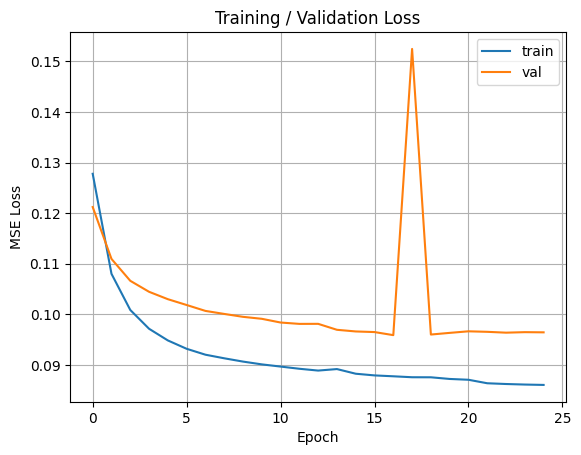

In [16]:
plt.plot(train_loss_history, label="train")
plt.plot(val_loss_history, label="val")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training / Validation Loss")
plt.legend()
plt.grid(True)
plt.savefig(RUN_DIR / 'loss_curves.png')
plt.show()

## 8. Inference / reconstruction error on validation & test sets

In [17]:

def per_channel_errors(loader, model, device):
    """MSE per channel error reconstruction, avg over the sliding window, but not across 65 parameters.
    Returns (n_windows, n_features)."""
    
    model.eval()
    errs = []

    with torch.no_grad():
        for x, _ in loader:            
            x = x.to(device, non_blocking=True)
            reconstructions = model(x)
            err = ((reconstructions - x) ** 2).mean(dim=1)  #(batch,65)
            errs.append(err.cpu().numpy()) #Converting tensors to numpy arrays
    if not errs:
         raise ValueError("No windows were produced by the loader")
    return np.concatenate(errs, axis=0)

# Getting per channel errors for validation and test sets
val_pc_err = per_channel_errors(val_loader, model, device)
test_pc_err = per_channel_errors(test_loader, model, device)

#test_labels = test_df["is_anomaly"].to_numpy(np.int8)[WINDOW_SIZE - 1:]
# Window level, any anomaly
def window_any_anomaly(raw_labels, window_size):
    """Mark a window anomalous if any timestep in it is anomalous."""
    return np.lib.stride_tricks.sliding_window_view(
        raw_labels , window_shape= window_size
    ).max(axis=1)

valid_window_labels = window_any_anomaly(valid_labels, WINDOW_SIZE)
test_window_labels = window_any_anomaly(test_labels, WINDOW_SIZE)

#Reconstruction error statistics for the validation set, only using windows with no anomalies
clean_mask = valid_window_labels == 0
if not np.any(clean_mask):
    raise ValueError("Validation set has no clean windows; cannot estimate clean reconstruction statistics")

mu_rec_err = val_pc_err[clean_mask].mean(axis=0)
raw_sigma_rec_err = val_pc_err[clean_mask].std(axis=0)
MIN_REC_SIGMA = float(cfg["metrics"]["min_rec_sigma"])
sigma_rec_err = np.maximum(raw_sigma_rec_err, MIN_REC_SIGMA)

print(f"Clean validation windows: {int(clean_mask.sum())}/{len(clean_mask)}")
print(f"Channels floored at MIN_REC_SIGMA={MIN_REC_SIGMA}: {(raw_sigma_rec_err < MIN_REC_SIGMA).sum()} / {len(raw_sigma_rec_err)}")
print("Raw clean-validation sigma percentiles:",
      np.percentile(raw_sigma_rec_err, [0, 1, 5, 25, 50, 75, 95, 99, 100]))

TOP_K = cfg["metrics"]["top_k"]
if not 1 <= TOP_K <= val_pc_err.shape[1]:
    raise ValueError(f"top_k must be between 1 and {val_pc_err.shape[1]}, got {TOP_K}")

def channelwise_topk_score(errors_per_channel, mu_rec_err, sigma_rec_err, top_k=TOP_K):
    """ Mean of the largest top_k channel z-scores for each window """
    z = (errors_per_channel - mu_rec_err) / sigma_rec_err
    topk_z = np.partition(z, -top_k, axis=1)[:, -top_k:]
    return topk_z.mean(axis=1)

val_score = channelwise_topk_score(
    val_pc_err, mu_rec_err, sigma_rec_err, top_k=TOP_K
)

test_score = channelwise_topk_score(test_pc_err, mu_rec_err, sigma_rec_err, top_k=TOP_K)

print(f"Validation Per-Channel Errors: {val_pc_err.shape}")
print(f"Test Per-Channel Errors: {test_pc_err.shape}")
print(f"val_score: shape={val_score.shape}, min={val_score.min():.4f}, mean={val_score.mean():.4f}, max={val_score.max():.4f}")
print(f"test_score: shape={test_score.shape}, min={test_score.min():.4f}, mean={test_score.mean():.4f}, max={test_score.max():.4f}")
print(f"Valid window labels: {valid_window_labels.shape}, Test window labels: {test_window_labels.shape}")
# Save clean reconstruction statistics for live inference
clean_stats_path = RUN_DIR / 'clean_stats.npz'
np.savez(clean_stats_path,
         mu_rec_err=mu_rec_err,
         sigma_rec_err=sigma_rec_err,
         top_k=np.array(TOP_K),
         min_rec_sigma=np.array(MIN_REC_SIGMA))
print(f"Saved clean stats to {clean_stats_path}")


Clean validation windows: 171228/172741
Channels floored at MIN_REC_SIGMA=0.05: 56 / 65
Raw clean-validation sigma percentiles: [4.51635129e-09 6.25217735e-09 2.47973944e-08 4.77094659e-07
 8.58595711e-04 6.61674514e-03 1.57585639e-01 1.89105818e-01
 2.27655813e-01]
Validation Per-Channel Errors: (172741, 65)
Test Per-Channel Errors: (259141, 65)
val_score: shape=(172741,), min=-0.0000, mean=3.0596, max=1693.4897
test_score: shape=(259141,), min=0.0003, mean=5.1196, max=1420.9535
Valid window labels: (172741,), Test window labels: (259141,)
Saved clean stats to experiments/BASE-001/clean_stats.npz


## 9. Thresholding on Validation Set

Tune the anomaly detection threshold on the validation set using the Precision-Recall curve to maximize F1-score and suppress false alarms on normal telemetry.


In [18]:
from sklearn.metrics import precision_recall_curve, precision_score, recall_score, f1_score, fbeta_score

# Strategy: Tune threshold on validation set to maximize F1 (optimal balance of precision & recall)
strategy = cfg.get("metrics", {}).get("threshold_strategy", "f1_optimal")
target_recall = float(cfg.get("metrics", {}).get("target_recall", 0.95))

prec_val, rec_val, thresh_val = precision_recall_curve(valid_window_labels, val_score)
f1_val_curve= 2 * (prec_val * rec_val) / np.maximum(prec_val + rec_val, 1e-8)
f2_val_curve = 5 * prec_val * rec_val / np.maximum(4 * prec_val + rec_val, 1e-12)

idx_f1 = int(np.argmax(f1_val_curve[:-1]))
idx_f2 = int(np.argmax(f2_val_curve[:-1]))

target_idxs = np.flatnonzero(rec_val[:-1] >= target_recall)
if len(target_idxs):
    idx_target_recall = int(target_idxs[np.argmax(prec_val[target_idxs])])
else:
    # If target recall is not achievable on the PR threshold points, use the point with max recall.
    idx_target_recall = int(np.argmax(rec_val[:-1]))
    print(f"WARNING: target recall {target_recall:.3f} is not achievable by the PR threshold points; "
          f"best available recall is {rec_val[idx_target_recall]:.4f}.")

threshold_candidates = {
    "f1_optimal": float(thresh_val[idx_f1]),
    "f2_recall": float(thresh_val[idx_f2]),
    "target_recall": float(thresh_val[idx_target_recall]),
}

if strategy not in threshold_candidates:
    raise ValueError(
        f"Unsupported threshold_strategy={strategy!r}; choose one of {list(threshold_candidates)}"
    )

threshold = threshold_candidates[strategy]
LOCKED_VALIDATION_THRESHOLD = float(threshold)
persistence_window = int(cfg.get("metrics", {}).get("persistence_window", 1))
if persistence_window < 1:
    raise ValueError("persistence_window must be >= 1")


def apply_persistence_filter(preds, window_len):
    """Retain positive predictions that belong to a run of at least window_len windows."""
    preds = np.asarray(preds, dtype=np.int8)
    if window_len <= 1:
        return preds.copy()
    s = pd.Series(preds)
    fwd = s.rolling(window_len, min_periods=window_len).sum() == window_len
    bwd = s.iloc[::-1].rolling(window_len, min_periods=window_len).sum().iloc[::-1] == window_len
    return (fwd | bwd).astype(np.int8).to_numpy()

val_predictions_raw = (val_score >= LOCKED_VALIDATION_THRESHOLD).astype(np.int8)
valid_predictions = apply_persistence_filter(val_predictions_raw, persistence_window)

val_precision_raw = float(precision_score(valid_window_labels, val_predictions_raw, zero_division=0))
val_recall_raw = float(recall_score(valid_window_labels, val_predictions_raw, zero_division=0))
val_f1_raw = float(f1_score(valid_window_labels, val_predictions_raw, zero_division=0))
val_f2_raw = float(fbeta_score(valid_window_labels, val_predictions_raw, beta=2, zero_division=0))

val_precision = float(precision_score(valid_window_labels, valid_predictions, zero_division=0))
val_recall = float(recall_score(valid_window_labels, valid_predictions, zero_division=0))
val_f1 = float(f1_score(valid_window_labels, valid_predictions, zero_division=0))
val_f2 = float(fbeta_score(valid_window_labels, valid_predictions, beta=2, zero_division=0))

valid_predictions = (val_score > threshold).astype(int)
val_precision = precision_score(valid_window_labels, valid_predictions, zero_division=0)
val_recall = recall_score(valid_window_labels, valid_predictions, zero_division=0)
val_f1 = f1_score(valid_window_labels, valid_predictions, zero_division=0)

print("Validation-only threshold candidates:")
for candidate_name, candidate_threshold in threshold_candidates.items():
    candidate_idx = {"f1_optimal": idx_f1, "f2_recall": idx_f2, "target_recall": idx_target_recall}[candidate_name]
    print(f"  {candidate_name:14s} threshold={candidate_threshold:.6f} "
          f"PR precision={prec_val[candidate_idx]:.4f} recall={rec_val[candidate_idx]:.4f}")
print(f"Selected strategy: {strategy}")
print(f"Locked validation threshold: {LOCKED_VALIDATION_THRESHOLD:.6f}")
print(f"top_k={TOP_K} | min_rec_sigma={MIN_REC_SIGMA} | persistence_window={persistence_window}")
print("Validation metrics BEFORE persistence: "
      f"precision={val_precision_raw:.4f}, recall={val_recall_raw:.4f}, "
      f"F1={val_f1_raw:.4f}, F2={val_f2_raw:.4f}")
print("Validation metrics AFTER persistence:  "
      f"precision={val_precision:.4f}, recall={val_recall:.4f}, "
      f"F1={val_f1:.4f}, F2={val_f2:.4f}")
print(f"Validation window-level recall: {val_recall:.4f} ({val_recall*100:.2f}%)")

test_predictions = (test_score > threshold).astype(int)


Validation-only threshold candidates:
  f1_optimal     threshold=10.909085 PR precision=0.9978 recall=0.9161
  f2_recall      threshold=10.301443 PR precision=0.9858 recall=0.9187
  target_recall  threshold=3.929836 PR precision=0.7478 recall=0.9504
Selected strategy: f2_recall
Locked validation threshold: 10.301443
top_k=3 | min_rec_sigma=0.05 | persistence_window=3
Validation metrics BEFORE persistence: precision=0.9858, recall=0.9187, F1=0.9511, F2=0.9314
Validation metrics AFTER persistence:  precision=0.9858, recall=0.9180, F1=0.9507, F2=0.9316
Validation window-level recall: 0.9180 (91.80%)


In [19]:
from numpy.lib.stride_tricks import sliding_window_view

ev = pd.read_csv("data_fixed/eval/anomaly_labels.csv")
print(len(ev), "events in eval")

missed = (valid_window_labels == 1) & (val_score < threshold)
n_anom_frames = sliding_window_view(valid_labels, WINDOW_SIZE).sum(axis=1)  # anomalous frames per window

print("missed:", missed.sum(), "of", valid_window_labels.sum())
print("anomalous frames inside missed windows:")
print(pd.Series(n_anom_frames[missed]).describe())

for _, e in ev.iterrows():
    lo = max(0, e.start_step - WINDOW_SIZE + 1)
    hi = min(len(missed) - 1, e.end_step - 1)
    print(f"event {e.event_id}: {e.type:8s} sev={e.severity} params={e.params[:45]:45s} "
          f"missed {missed[lo:hi+1].sum()}/{valid_window_labels[lo:hi+1].sum()}")

10 events in eval
missed: 123 of 1513
anomalous frames inside missed windows:
count    123.000000
mean       9.349593
std        7.820720
min        1.000000
25%        3.000000
50%        7.000000
75%       14.500000
max       29.000000
dtype: float64
event 0: spike    sev=22.43 params=cpu_temperature_C                             missed 0/62
event 1: drift    sev=27.33 params=nav_vel_x_kms                                 missed 12/157
event 2: drift    sev=20.79 params=comm_snr_db                                   missed 16/167
event 3: multi    sev=18.86 params=thermistor_cpu_setpoint_C, solar_panel_curren missed 0/160
event 4: drift    sev=10.67 params=bus_temperature_C                             missed 56/151
event 5: drift    sev=23.62 params=rw_torque_3_nm                                missed 2/92
event 6: multi    sev=9.74 params=battery_temperature_C, thrust_force_N         missed 0/126
event 7: drift    sev=14.27 params=comm_active                                   missed 7

## 10.Evaluation Metrics(Recall, Precision, F1 Score and Confusion Matrix)


Recall: 0.7545
Precision: 0.9772
F1-Score: 0.8516
Confusion Matrix:
 [[255497     63]
 [   879   2702]]


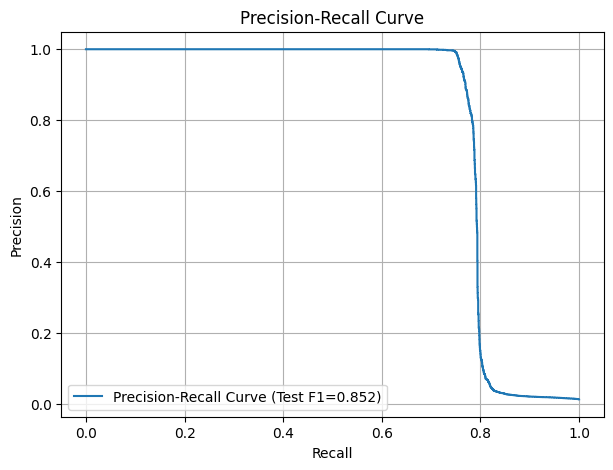

Appended summary row for 'BASE-001' -> experiments/ablation_results.csv


In [20]:
from sklearn.metrics import recall_score, precision_score, f1_score, confusion_matrix

recall = float(recall_score(test_window_labels, test_predictions))
precision = float(precision_score(test_window_labels, test_predictions))
f1 = float(f1_score(test_window_labels, test_predictions))
conf_matrix = confusion_matrix(test_window_labels, test_predictions)
prec_curve, rec_curve, pr_thresholds = precision_recall_curve(
    test_window_labels,
    test_score
)

print(f"Recall: {recall:.4f}")
print(f"Precision: {precision:.4f}")
print(f"F1-Score: {f1:.4f}")
print("Confusion Matrix:\n", conf_matrix)

plt.figure(figsize=(7, 5))
plt.plot(rec_curve, prec_curve, label=f"Precision-Recall Curve (Test F1={f1:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(True)
plt.savefig(RUN_DIR / 'pr_curve.png')
plt.show()

metrics = {
    "experiment_id": EXPERIMENT_ID,
    "baseline_id": BASELINE_ID,
    "threshold": float(threshold),
    "recall": float(recall),
    "precision": float(precision),
    "f1": float(f1),
    "confusion_matrix": conf_matrix.tolist(),
    "best_epoch": best_epoch,
    "best_val_loss": float(best_val_loss),
    "test_loss": float(test_pc_err.mean()),
    "total_train_time": float(total_train_time) if "total_train_time" in locals() else 0.0,
    "seed": SEED,
}
with open(RUN_DIR / "config.json", "w") as f:
    json.dump(cfg, f, indent=2)

with open(RUN_DIR / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

summary_row = {
    "experiment_id": EXPERIMENT_ID,
    "baseline_id": BASELINE_ID,
    "experiment_type": cfg.get("experiment_type"),
    "window_size": WINDOW_SIZE,
    "batch_size": BATCH_SIZE,
    "hidden_dim": HIDDEN_DIM,
    "num_layers": NUM_LAYERS,
    "lr": LR,
    "use_amp": USE_AMP,
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
    "test_loss": float(test_pc_err.mean()),
    "total_train_time": total_train_time if "total_train_time" in locals() else 0.0,
    "seed": SEED,
    "threshold": threshold,
    "recall": recall,
    "precision": precision,
    "f1": f1,
}

master_csv = RESULTS_ROOT / "ablation_results.csv"
row_df = pd.DataFrame([summary_row])
row_df.to_csv(master_csv, mode="a", header=not master_csv.exists(), index=False)

print(f"Appended summary row for '{EXPERIMENT_ID}' -> {master_csv}")


## (Optional) Checking the Shape

In [18]:
print("test_labels:")
print(test_labels[:10])
print("shape:", test_labels.shape)
print("dtype:", test_labels.dtype)
print("unique:", np.unique(test_labels))

print("\ntest_predictions:")
print(test_predictions[:10])
print("shape:", test_predictions.shape)
print("dtype:", test_predictions.dtype)
print("unique:", np.unique(test_predictions))

test_labels:
[0 0 0 0 0 0 0 0 0 0]
shape: (259200,)
dtype: int8
unique: [0 1]

test_predictions:
[0 0 0 0 0 0 0 0 0 0]
shape: (259141,)
dtype: int64
unique: [0 1]


## (Optional) Other levers if you're still tight on resources

- **Smaller `hidden_dim`**: 128 → 64 halves the LSTM's parameter count and activation memory with
  usually modest reconstruction-quality loss for a 65-feature input.
- **Shorter `WINDOW_SIZE`**: 60 → 30 halves per-sample sequence length, which for an LSTM roughly
  halves both compute and backprop-through-time memory.
- **Subsample training windows**: since consecutive windows overlap by `window_size - 1` timesteps,
  you can stride the dataset (e.g. take every 5th window) for a large speedup with limited loss of
  training diversity — add a `stride` param to `WindowedTimeSeriesDataset.__init__` and use
  `idx * stride` in `__getitem__`.
- **`torch.set_num_threads(N)`**: on CPU-only laptops, pin this to your physical core count
  (not hyperthreads) — oversubscription from BLAS + DataLoader workers competing for cores is a
  common silent slowdown.
- **Close other memory-heavy apps** (browser tabs, IDEs) before the training cell — Jupyter itself
  plus a browser can easily eat 1-2 GB, which matters when you're already near the ceiling.
- **`gc.collect()` + `del` intermediate DataFrames** (already done in step 4) after each stage so
  peak RAM is bounded by the *largest single stage*, not the sum of all stages.
